# Day 10 – Environmental Exploratory Data Analysis (EDA)

## Objective

The objective of this notebook is to explore the temporal and statistical characteristics of the processed water-quality dataset.

The analysis includes:

- Parameter distributions
- Temporal trends
- Correlations between parameters
- Cross-parameter interactions
- Candidate anomaly identification
- Temporal pattern inspection
- Hypotheses for anomaly detection
- Hypotheses for future-value forecasting

The timestamps used in this analysis are synthetically generated because the original dataset does not contain temporal information. They are used only for methodological temporal analysis and do not represent actual sensor collection times.

The original raw dataset remains unchanged.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

processed_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\data\processed\water_quality_timestamped.csv"

df = pd.read_csv(processed_path)

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df = df.sort_values("timestamp").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (3276, 11)
Columns:
['timestamp', 'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']


,timestamp,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,2025-01-01 00:00:00,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,2025-01-01 01:00:00,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,2025-01-01 02:00:00,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,2025-01-01 03:00:00,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,2025-01-01 04:00:00,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [3]:
numeric_columns = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != "Potability"
]

print("Numeric parameters:")
print(numeric_columns)

Numeric parameters:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


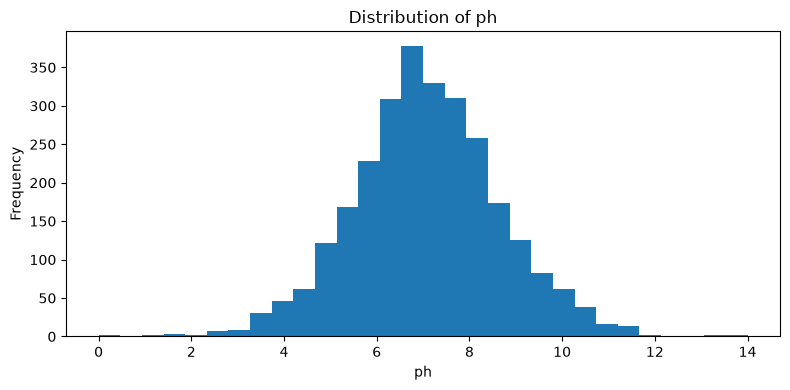

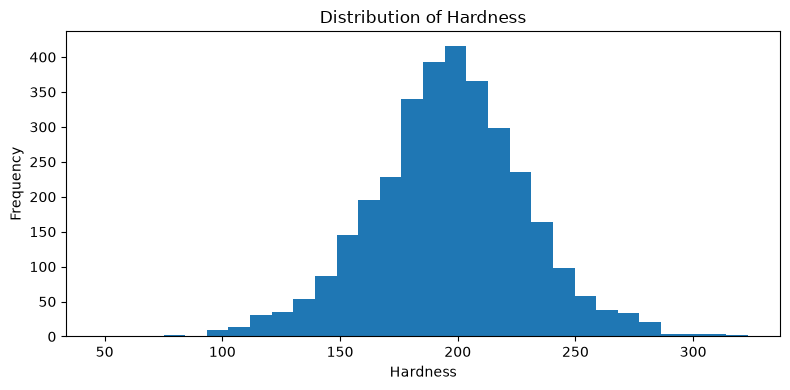

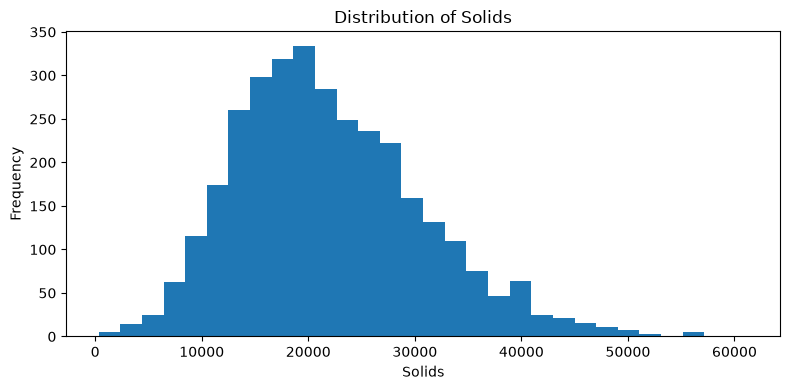

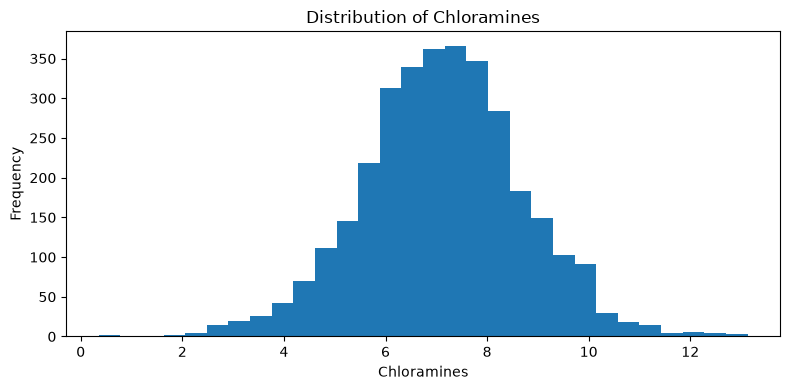

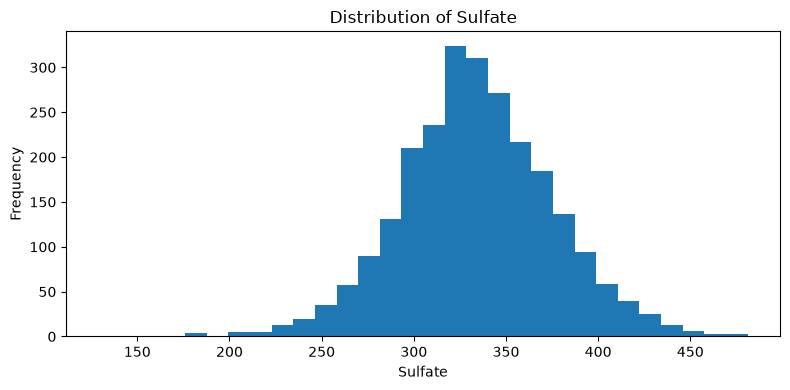

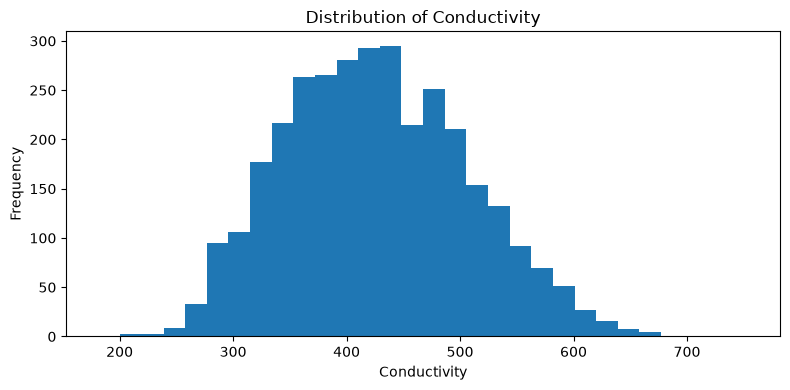

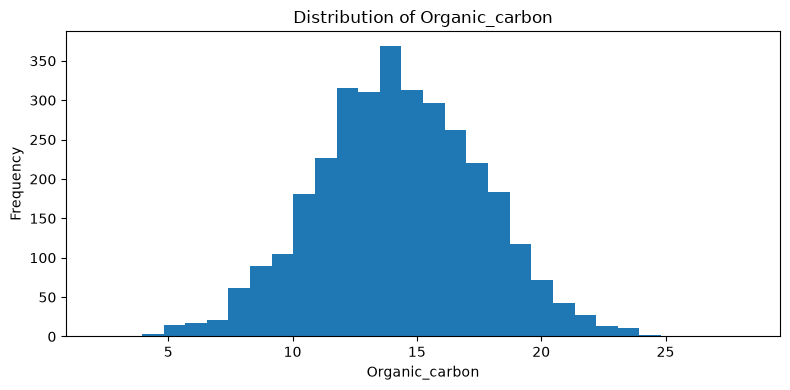

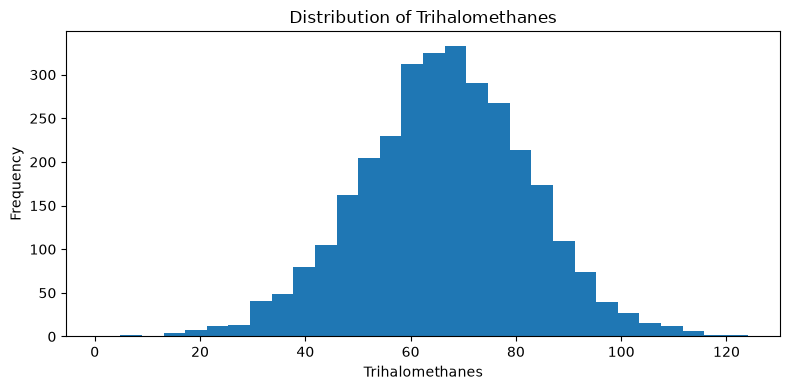

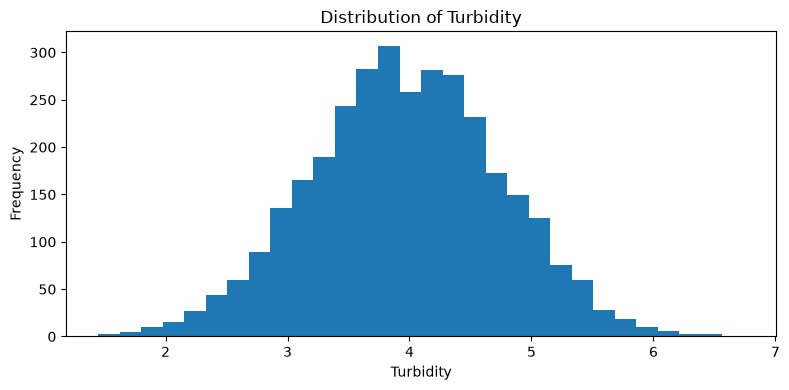

In [4]:
for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(df[column].dropna(), bins=30)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [5]:
correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix.round(2))

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
ph,1.00,0.08,-0.09,-0.03,0.02,0.02,0.04,0.00,-0.04
Hardness,0.08,1.00,-0.05,-0.03,-0.11,-0.02,0.00,-0.01,-0.01
Solids,-0.09,-0.05,1.00,-0.07,-0.17,0.01,0.01,-0.01,0.02
Chloramines,-0.03,-0.03,-0.07,1.00,0.03,-0.02,-0.01,0.02,0.00
Sulfate,0.02,-0.11,-0.17,0.03,1.00,-0.02,0.03,-0.03,-0.01
Conductivity,0.02,-0.02,0.01,-0.02,-0.02,1.00,0.02,0.00,0.01
Organic_carbon,0.04,0.00,0.01,-0.01,0.03,0.02,1.00,-0.01,-0.03
Trihalomethanes,0.00,-0.01,-0.01,0.02,-0.03,0.00,-0.01,1.00,-0.02
Turbidity,-0.04,-0.01,0.02,0.00,-0.01,0.01,-0.03,-0.02,1.00


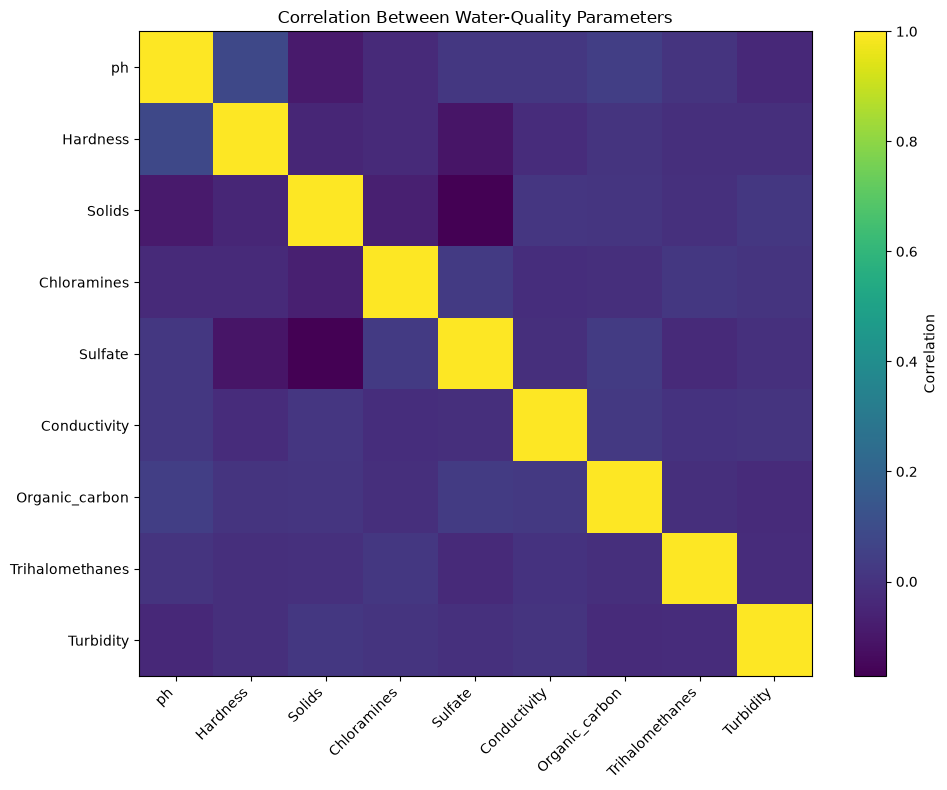

In [6]:
plt.figure(figsize=(10, 8))

plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Between Water-Quality Parameters")
plt.tight_layout()
plt.show()

In [7]:
candidate_anomalies = pd.DataFrame(index=df.index)

for column in numeric_columns:
    mean_value = df[column].mean()
    std_value = df[column].std()

    candidate_anomalies[column] = (
        (df[column] - mean_value).abs() / std_value
    )

candidate_anomalies["max_z_score"] = candidate_anomalies.max(axis=1)

candidate_anomalies["anomaly_candidate"] = (
    candidate_anomalies["max_z_score"] > 3
)

print(
    "Candidate anomaly records:",
    candidate_anomalies["anomaly_candidate"].sum()
)

display(
    df.loc[
        candidate_anomalies["anomaly_candidate"],
        ["timestamp"] + numeric_columns
    ].head(20)
)

Candidate anomaly records: 115


,timestamp,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
37,2025-01-02 13:00:00,5.618064,304.235912,17281.975168,6.101084,NaN,399.471566,12.265002,81.588992,2.896547
66,2025-01-03 18:00:00,5.058109,238.569380,34873.934523,8.983276,374.433505,669.725086,13.353181,76.521800,5.106656
80,2025-01-04 08:00:00,1.844538,233.764343,28689.595778,7.724432,NaN,410.387264,15.611859,54.299444,5.013463
88,2025-01-04 16:00:00,10.155440,300.292476,12652.362979,6.655126,398.647786,487.459131,9.347634,67.919789,5.002467
140,2025-01-06 20:00:00,8.594416,270.022706,15791.675351,5.912691,NaN,672.556999,20.184051,54.961285,3.568992
253,2025-01-11 12:15:00,6.800119,242.008082,39143.403329,9.501695,187.170714,376.456593,11.432466,73.777275,3.854940
263,2025-01-11 22:15:00,13.175402,47.432000,19237.949676,8.907020,375.147315,500.245952,12.083896,NaN,4.106924
272,2025-01-12 07:15:00,6.512737,229.263861,22475.046873,12.580026,192.033592,479.501279,9.983462,66.668576,4.612964
275,2025-01-12 10:15:00,5.324942,280.089655,35344.658047,13.043806,180.206746,392.421496,10.504820,55.084668,4.427138
278,2025-01-12 13:15:00,10.761898,81.710895,25999.953669,8.477394,318.427241,392.704082,12.716350,52.246972,4.661799


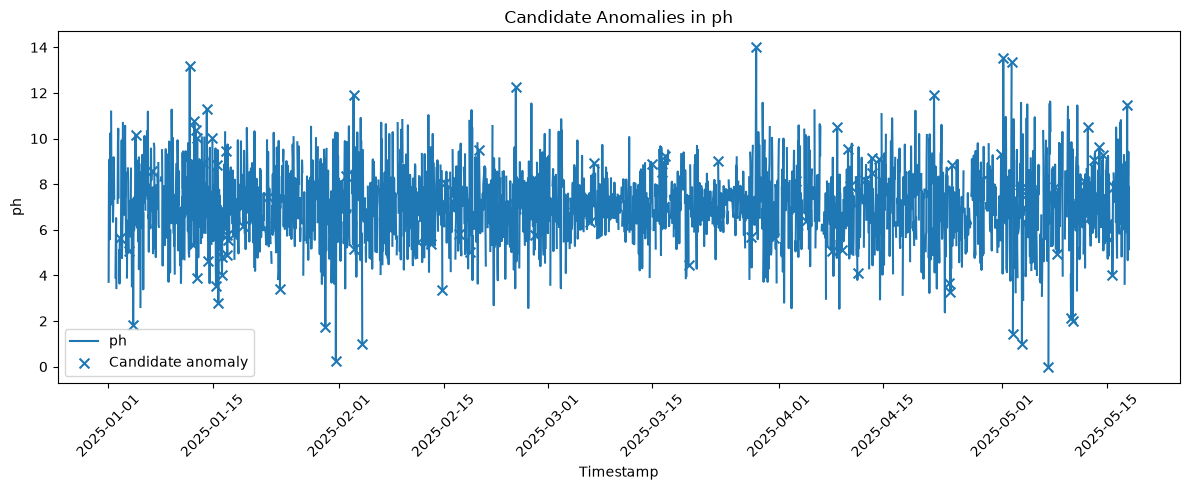

In [8]:
anomaly_points = df.loc[
    candidate_anomalies["anomaly_candidate"]
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df[numeric_columns[0]],
    label=numeric_columns[0]
)

plt.scatter(
    anomaly_points["timestamp"],
    anomaly_points[numeric_columns[0]],
    marker="x",
    s=50,
    label="Candidate anomaly"
)

plt.title(f"Candidate Anomalies in {numeric_columns[0]}")
plt.xlabel("Timestamp")
plt.ylabel(numeric_columns[0])
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## Day 10 – EDA Observations

### Distribution Findings

- Water-quality parameters show different statistical distributions and ranges.
- Some parameters show skewed distributions.
- Extreme observations are visible in selected parameters and require further investigation.

### Temporal Findings

- Temporal plots show sudden spikes and drops in some parameters.
- Several observations differ substantially from their surrounding values.
- Because timestamps were synthetically generated, these patterns are treated as methodological candidate anomalies rather than confirmed environmental events.

### Correlation Findings

- Correlation analysis shows varying degrees of linear association between water-quality parameters.
- Some parameter pairs show stronger relationships, while others show weak relationships.
- These relationships may provide useful features for multivariate anomaly detection and forecasting.

### Candidate Anomaly Hypothesis

Observations with unusually large deviations from their parameter mean may represent candidate anomalies.

A statistical threshold such as a z-score greater than 3 can be used as an initial screening baseline. These candidates should later be compared with model-based anomaly detection methods such as Isolation Forest.

### Forecasting Hypothesis

Historical parameter values and relationships between parameters may contain information useful for predicting future observations.

However, because the timestamps are synthetic and the source dataset is not a true longitudinal sensor dataset, forecasting results will be interpreted as methodological experiments rather than real-world environmental forecasts.